In [73]:
from typing import Callable, Literal

import duckdb
import matplotlib.pyplot as plt
import numpy as np
from numpy.typing import ArrayLike
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, ndcg_score
from sklearn.model_selection import train_test_split, GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils import check_X_y, check_array
from scipy.sparse import csr_array, issparse, spmatrix, sparray, vstack

from recommender_fm import mean_lowest_scorer, mean_lowest_rating, ndcg_p_score

In [74]:
def per_var_split_mask(
        df_sorted: pd.DataFrame,
        var: str,
        test_ratio=0.01,
        test_min_per_var=10,
):
    per_var_count = df_sorted[var].map(df_sorted[var].value_counts())
    per_var_ranks = df_sorted.groupby(var).cumcount(ascending=False)
    per_var_test_size = np.maximum(test_min_per_var, test_ratio * per_var_count)
    test_mask = per_var_ranks < per_var_test_size
    
    return test_mask

In [75]:
def per_var_temporal_split(
        X: pd.DataFrame,
        y: ArrayLike,
        var="user_id",
        time_col="timestamp",
        test_ratio=0.01,
        test_min_per_var=10,
):
    sort_indices = X.sort_values(by=[var, time_col]).index
    X_sorted = X.loc[sort_indices]
    y_sorted = pd.Series(y, index=X.index).loc[sort_indices]
    test_mask = per_var_split_mask(X_sorted, var, test_ratio, test_min_per_var)
    return X_sorted[~test_mask], X_sorted[test_mask], y_sorted[~test_mask], y_sorted[test_mask]

In [76]:
dataset = ArrayLike | spmatrix | sparray


def _predict_y_fm(X, w0, weights, factors):
    X_dot_factors = X @ factors
    X_dot_factors_squares = X ** 2 @ (factors ** 2)
    interactions = np.sum(X_dot_factors ** 2 - X_dot_factors_squares, axis=1) / 2
    linear_part = X @ weights
    return w0 + linear_part + interactions, X_dot_factors


def _process_X_y(X, y):
    X, y = check_X_y(X, y, accept_sparse=["csr"])
    if issparse(X):
        X = csr_array(X)
    return X, y


def _prepare_split_data(X, y, eval_set):
    X, y = _process_X_y(X, y)
    X_eval, y_eval = X, y
    if eval_set is not None:
        X_eval, y_eval = _process_X_y(eval_set[0], eval_set[1])
    return X, X_eval, y, y_eval


class FactorizationMachine:
    def __init__(
            self, 
            factors_num: int = 1, 
            num_recommend=5,
            max_epoch=1000,
            tol=1e-4,
            learn_rate=0.01,
            loss: str | Callable[[ArrayLike, ArrayLike], float] = "mse",
            dloss_dpred: Callable[[ArrayLike, ArrayLike], ArrayLike] | None = None,
            metric: Literal["neg_rmse", "mean_lowest_per_user", "ndcg"] = "neg_rmse",
            weights_penalty=0,
            factors_penalty=0,
            batch_size=1000,
            patience=5,
            random_state=None,
            verbose=False,
    ):
        self._init_loss(loss, dloss_dpred)
        self.metric = metric
        self.factors_num = factors_num
        self.num_recommend = num_recommend
        self.max_epoch = max_epoch
        self.tol = tol
        self.learn_rate = learn_rate
        self.patience = patience
        self.batch_size = batch_size
        self.random_state = random_state
        self.weights_penalty = weights_penalty
        self.factors_penalty = factors_penalty
        self.verbose = verbose

    def _init_loss(self, loss, dloss_dpred):
        if loss == "mse":
            self.loss = lambda y, y_pred: np.mean((y - y_pred) ** 2)
            self.dloss_dpred = lambda y, y_pred: 2 * (y_pred - y) / y.shape[0]
        else:
            self.loss = loss
            self.dloss_dpred = dloss_dpred

    def _init_params(
            self, 
            dim: int, 
            y: ArrayLike,
            rng
    ):
        self._w0 = np.mean(y)
        self._weights = np.zeros(shape=(dim,), dtype=float)

        init_std = np.sqrt(2.0 / (dim + self.factors_num))
        self._factors = rng.normal(
            scale=init_std, 
            size=(dim, self.factors_num),
        )
        self._no_improvement_count = 0
        self._best_score = -np.inf

        self._squared_weight_grads = np.zeros(dim)
        self._squared_factor_grads = np.zeros((dim, self.factors_num))
        self._squared_w0_grads = 0.0

    def _run_epoch(self, X, y, n_samples, rng):
        permutation = rng.permutation(n_samples)
        for i in range(0, n_samples, self.batch_size):
            batch_indices = permutation[i : i + self.batch_size]
            self._update_batch(X[batch_indices], y[batch_indices])

    def _update_coef(self, coef, grad, squared_grads):
        squared_grads += np.square(grad)
        curr_learn_rate = self.learn_rate / np.sqrt(squared_grads + 1e-8)
        coef -= curr_learn_rate * grad
        return coef, squared_grads

    def _update_batch(self, X_batch, y_batch):
        y_pred_batch, X_dot_factors = self._predict(X_batch)
        dloss_dpred = self.dloss_dpred(y_batch, y_pred_batch)

        w0_grad = np.sum(dloss_dpred)
        self._w0, self._squared_w0_grads = self._update_coef(
            self._w0, w0_grad, self._squared_w0_grads,
        )

        weights_grad = X_batch.T @ dloss_dpred \
                    + 2 * self.weights_penalty * self._weights
        self._weights, self._squared_weight_grads = self._update_coef(
            self._weights, weights_grad, self._squared_weight_grads,
        )

        factor_coef_0 = X_batch.T @ (dloss_dpred[:, np.newaxis] * X_dot_factors)
        factor_coef_1 = -(X_batch.T ** 2) @ dloss_dpred
        factors_grad = factor_coef_0 \
                        + factor_coef_1[:, np.newaxis] * self._factors \
                        + 2 * self.factors_penalty * self._factors

        self._factors, self._squared_factor_grads = self._update_coef(
            self._factors, factors_grad, self._squared_factor_grads,
        )
    
    def _count_loss(self, X, y):
        y_pred = self._predict(X)[0]
        return self.loss(y_pred, y)

    def _is_converged(self, X_eval, y_eval, users=None):
        curr_score = self.score(X_eval, y_eval, users)

        if curr_score > self._best_score + self.tol:
            self._best_score = curr_score
            self._no_improvement_count = 0
        else:
            self._no_improvement_count += 1

        if self._no_improvement_count >= self.patience:
            return True
        else:
            return False

    def fit(
            self,
            X: dataset,
            y: ArrayLike,
            eval_set: tuple[ArrayLike, ArrayLike] | None = None,
            users=None,
    ):
        X_train, X_eval, y_train, y_eval = _prepare_split_data(X, y, eval_set)
        n_samples, dim = X.shape
        rng = np.random.default_rng(seed=self.random_state)

        self._init_params(dim, y_train, rng)
        self.best_epoch = self.max_epoch

        for epoch in range(self.max_epoch):
            self._run_epoch(X_train, y_train, n_samples, rng)
            is_converged = self._is_converged(X_eval, y_eval, users)
            if eval_set is not None:
                if is_converged:
                    self.best_epoch = epoch
                    break

            if self.verbose == True and epoch % 10 == 0:
                print(
                    f"Epoch {epoch}, factors num {self.factors_num}, \n"
                    f"factors abs mean: {np.mean(np.abs(self._factors))}, \n"
                    f"weights abs mean: {np.mean(np.abs(self._weights))}, \n"
                    f"intercept {self._w0}, best {self.metric} score {self._best_score}"
                )

        if eval_set is not None:
            X_all = vstack([X_train, X_eval])
            y_all = np.concatenate([y_train, y_eval])
            self.max_epoch = self.best_epoch
            return self.fit(X_all, y_all, None, None)
        
        self.best_epoch = self.max_epoch
        self.fitted_ = True
        return self

    def _predict(self, X):
        return _predict_y_fm(X, self._w0, self._weights, self._factors)

    def predict(self, X):
        X = check_array(X, accept_sparse=["csr"])
        if issparse(X):
            X = csr_array(X)
        return self._predict(X)[0]

    def score(self, X, y, users=None):
        y_pred = self.predict(X)
        if self.metric == "neg_rmse":
            return -root_mean_squared_error(y, y_pred)
        if self.metric == "mean_lowest_per_user":
            return mean_lowest_rating(
                y, y_pred, users=users, num_recommend=self.num_recommend
            )
        if self.metric == "ndcg":
            return ndcg_p_score(y, y_pred, users, p=self.num_recommend)
        else:
            raise NotImplementedError



## Movies dataset

MovieLens100k and MovieLens1M can't be used together -- users' ids don't match.

In [77]:
with duckdb.connect("/home/maria-khanina/mkgit/movies_project/data/database.duckdb", read_only=True) as db_conn:
    ratings_df = db_conn.execute("""
        SELECT *
        FROM ratings INNER JOIN movies USING (movie_id)
    """).df()


In [78]:
ratings_df.head()

,user_id,movie_id,rating,timestamp,title,genres
0,1,1193,5,978300760,One Flew Over the Cuckoo's Nest (1975),Drama
1,1,661,3,978302109,James and the Giant Peach (1996),Animation|Children's|Musical
2,1,914,3,978301968,My Fair Lady (1964),Musical|Romance
3,1,3408,4,978300275,Erin Brockovich (2000),Drama
4,1,2355,5,978824291,"Bug's Life, A (1998)",Animation|Children's|Comedy


In [79]:
ratings_df.shape

(1000209, 6)

In [80]:
ratings_df.isna().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
title        0
genres       0
dtype: int64

In [81]:
ratings_df["rating"].value_counts().sort_index()

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64

In [82]:
ratings_df["movie_id"].min(), ratings_df["user_id"].min()

(np.int64(1), np.int64(1))

In [83]:
ratings_df["movie_id"].max(), ratings_df["user_id"].max()

(np.int64(3952), np.int64(6040))

In [84]:
ratings_df["movie_id"].nunique(), ratings_df["user_id"].nunique()

(3706, 6040)

In [85]:
groupby_user = ratings_df.groupby("user_id")
time_range = groupby_user["timestamp"].max() - groupby_user["timestamp"].min()
days_range = time_range / (60 * 60 * 24)

In [86]:
days_range.min(), days_range.median(), days_range.max()

(np.float64(0.0012268518518518518),
 np.float64(0.04708912037037037),
 np.float64(1032.9605555555556))

In [87]:
(days_range > 7).mean()

np.float64(0.29751655629139073)

In [88]:
X_train_all, X_test, y_train_all, y_test = per_var_temporal_split(
    X=ratings_df.drop(columns="rating"),
    y=ratings_df["rating"],
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

In [89]:
X_train_all.shape, X_test.shape, y_train_all.shape, y_test.shape

((939685, 5), (60524, 5), (939685,), (60524,))

In [90]:
X_train_all["user_id"].nunique(), X_test["user_id"].nunique()

(6040, 6040)

In [91]:
(X_train_all.groupby("user_id")["timestamp"].max() > X_test.groupby("user_id")["timestamp"].min()).sum()

np.int64(0)

In [92]:
X_train_big, X_outer_val, y_train_big, y_outer_val = per_var_temporal_split(
    X_train_all,
    y_train_all,
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

In [93]:
X_train, X_val, y_train, y_val = per_var_temporal_split(
    X_train_big,
    y_train_big,
    var="user_id",
    time_col="timestamp",
    test_ratio=0.01,
    test_min_per_var=10,
)

### Median number of movies rated per user:

In [94]:
X_train.groupby("user_id").size().median()

np.float64(86.0)

In [95]:
X_train.groupby("movie_id").size().median()

np.float64(104.0)

([<matplotlib.axis.XTick at 0x743ea180cd70>,
 [Text(0, 0, '0'),
  Text(50, 0, '50'),
  Text(100, 0, '100'),
  Text(150, 0, '150'),
  Text(200, 0, '200'),
  Text(250, 0, '250'),
  Text(300, 0, '300'),
  Text(350, 0, '350'),
  Text(400, 0, '400'),
  Text(450, 0, '450'),
  Text(500, 0, '500'),
  Text(550, 0, '550'),
  Text(600, 0, '600'),
  Text(650, 0, '650'),
  Text(700, 0, '700'),
  Text(750, 0, '750'),
  Text(800, 0, '800'),
  Text(850, 0, '850'),
  Text(900, 0, '900'),
  Text(950, 0, '950'),
  Text(1000, 0, '1000'),
  Text(1050, 0, '1050'),
  Text(1100, 0, '1100'),
  Text(1150, 0, '1150'),
  Text(1200, 0, '1200'),
  Text(1250, 0, '1250'),
  Text(1300, 0, '1300'),
  Text(1350, 0, '1350'),
  Text(1400, 0, '1400'),
  Text(1450, 0, '1450'),
  Text(1500, 0, '1500'),
  Text(1550, 0, '1550'),
  Text(1600, 0, '1600'),
  Text(1650, 0, '1650'),
  Text(1700, 0, '1700'),
  Text(1750, 0, '1750'),
  Text(1800, 0, '1800'),
  Text(1850, 0, '1850'),
  Text(1900, 0, '1900'),
  Text(1950, 0, '1950')])

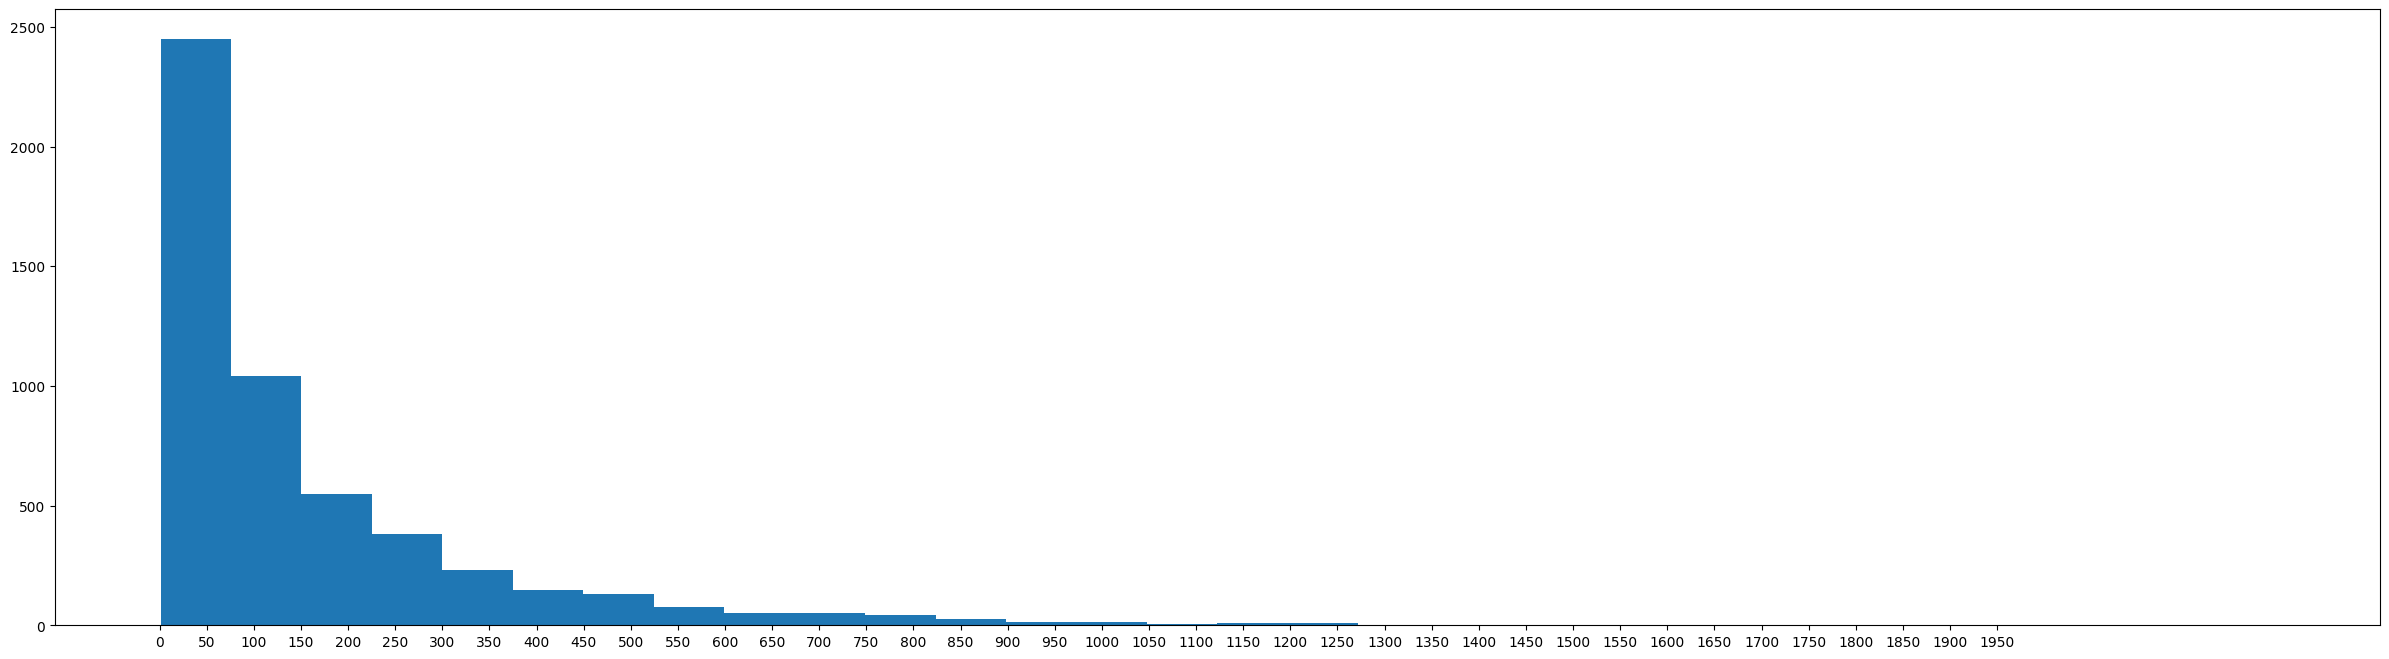

In [96]:
d = X_train.groupby("user_id").size()
plt.figure(figsize=(30, 8))
plt.hist(d, bins=30)
plt.xticks(range(0, 2000, 50))

### Average train rating as prediction

In [97]:
df_train = pd.concat((X_train_big, y_train_big), axis="columns")
avg_total = df_train["rating"].mean()
avg_train_ratings = df_train.groupby("movie_id", as_index=False)["rating"].mean()
avg_train_ratings.columns = ["movie_id", "avg_movie_rating"]

In [98]:
df_outer_val = pd.merge(left=X_outer_val, right=avg_train_ratings, on="movie_id", how="left")
df_outer_val["avg_movie_rating"] = df_outer_val["avg_movie_rating"].fillna(avg_total)

In [99]:
root_mean_squared_error(y_outer_val, df_outer_val["avg_movie_rating"])

0.996853495827109

In [100]:
mean_lowest_rating(
    true_ratings=y_outer_val,
    predicted_ratings=df_outer_val["avg_movie_rating"],
    users=df_outer_val["user_id"],
    num_recommend=5,
)

np.float64(3.4201909959072307)

In [101]:
ndcg_p_score(
    y_outer_val,
    df_outer_val["avg_movie_rating"],
    df_outer_val["user_id"],
    p=5,
)

np.float64(0.12215801794486673)

### Factorization Machine with only encoded user_id and movie_id as features

In [102]:
all_users = np.sort(X_train["user_id"].unique())
all_movies = np.sort(X_train["movie_id"].unique())

In [103]:
basic_transformer = ColumnTransformer(
    transformers=[
        (
            "encode_id",
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
)

In [104]:
basic_fm = FactorizationMachine(
    verbose=True,
    metric="mean_lowest_per_user",
    tol=1e-4,
    factors_num=20,
)

In [105]:
X_train_transformed = basic_transformer.fit_transform(X_train)
X_val_transformed = basic_transformer.transform(X_val)
X_outer_val_transformed = basic_transformer.transform(X_outer_val)

In [106]:
basic_fm.fit(
    X_train_transformed, 
    y_train, 
    eval_set=(X_val_transformed, y_val),
    users=X_val["user_id"],
)

Epoch 0, factors num 20, 
factors abs mean: 0.04655548923202358, 
weights abs mean: 0.060195564245028005, 
intercept 3.511450177593735, best mean_lowest_per_user score 2.856902922405106
Epoch 10, factors num 20, 
factors abs mean: 0.11687856016199258, 
weights abs mean: 0.11149890681897744, 
intercept 3.4077619703470097, best mean_lowest_per_user score 2.9051058112193484
Epoch 20, factors num 20, 
factors abs mean: 0.13181084138816906, 
weights abs mean: 0.12260763030942996, 
intercept 3.385191114792094, best mean_lowest_per_user score 2.9143432986227746
Epoch 30, factors num 20, 
factors abs mean: 0.14116864821784825, 
weights abs mean: 0.12893654260704288, 
intercept 3.37070628515031, best mean_lowest_per_user score 2.9182062479005713
Epoch 40, factors num 20, 
factors abs mean: 0.14837691550509932, 
weights abs mean: 0.13332948521096616, 
intercept 3.3608163378615714, best mean_lowest_per_user score 2.922741014444071
Epoch 0, factors num 20, 
factors abs mean: 0.04915721874562871, 


In [107]:
val_predictions = basic_fm.predict(X_outer_val_transformed)

In [108]:
mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], 5)

np.float64(2.9346026490066226)

In [109]:
y_pred_clipped = np.clip(val_predictions, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9284466509794472

In [110]:
ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], p=5)

np.float64(0.7926900887856366)

In [111]:
basic_fm.metric = "ndcg"
basic_fm.fit(
    X_train_transformed, 
    y_train, 
    eval_set=(X_val_transformed, y_val),
    users=X_val["user_id"],
)

Epoch 0, factors num 20, 
factors abs mean: 0.047175572799255265, 
weights abs mean: 0.06016137847566866, 
intercept 3.5050604872313693, best ndcg score 0.7795009864491096
Epoch 10, factors num 20, 
factors abs mean: 0.11730019642079141, 
weights abs mean: 0.11138311735295862, 
intercept 3.398703919528154, best ndcg score 0.7950056842104907
Epoch 20, factors num 20, 
factors abs mean: 0.13231793072804815, 
weights abs mean: 0.12264308156848207, 
intercept 3.372991270341051, best ndcg score 0.7992692944514403
Epoch 30, factors num 20, 
factors abs mean: 0.14166988652225276, 
weights abs mean: 0.12909752303902178, 
intercept 3.359728279408444, best ndcg score 0.8013204370245683
Epoch 40, factors num 20, 
factors abs mean: 0.14881771615060652, 
weights abs mean: 0.13355864877197776, 
intercept 3.349395148779926, best ndcg score 0.8027871650521389
Epoch 0, factors num 20, 
factors abs mean: 0.05213758435805822, 
weights abs mean: 0.06250344609471395, 
intercept 3.4937605593232153, best ndc

In [112]:
val_predictions = basic_fm.predict(X_outer_val_transformed)
ndcg_p_score(y_outer_val, val_predictions, X_outer_val["user_id"], p=5)

np.float64(0.7930276831357129)

In [113]:
mean_lowest_rating(y_outer_val, val_predictions, X_outer_val["user_id"], 5)

np.float64(2.9334437086092717)

In [114]:
y_pred_clipped = np.clip(val_predictions, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9303722365058686

### Factorization Machine with user's preferences added to features

In [115]:
class UserHistoryTransformer(TransformerMixin, BaseEstimator):
    def __init__(
            self, 
            user_col="user_id",
            item_col="movie_id",
            rating_max=5.0,
    ):
        self.user_col = user_col
        self.item_col = item_col
        self.rating_max = rating_max

    def fit(self, X, y):
        y_scaled = y / self.rating_max
        self._user_history = csr_array(
            (y_scaled, (X[self.user_col], X[self.item_col])),
        )
        return self
    
    def transform(self, X):
        users = X[self.user_col].values
        items = X[self.item_col].values
        
        X_history = self._user_history[users].copy()
        X_history[np.arange(len(X)), items] = 0
        X_history.eliminate_zeros()
        
        return X_history


### Testing transformer works as expected:

In [116]:
X_transformed = UserHistoryTransformer().fit(X_train, y_train).transform(X_train)

KeyboardInterrupt: 

In [ ]:
row_idx = 239
user_id = X_train.iloc[row_idx]["user_id"]
movie_id = X_train.iloc[row_idx]["movie_id"]
actual_rating = y_train.iloc[row_idx] / 5.0
one_row = X_transformed[row_idx].toarray()
one_row

array([0., 0., 0., ..., 0., 0., 0.], shape=(3953,))

In [ ]:
one_row[2491]

np.float64(0.0)

In [ ]:
np.argmax(one_row[2:])

np.int64(27)

In [ ]:
np.argmax(one_row[2:] == 0.8)

np.int64(30)

In [ ]:
one_row[3]

np.float64(0.0)

In [ ]:
one_row[49]

np.float64(0.0)

In [ ]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 47)]

,user_id,movie_id,rating,timestamp,title,genres
80917,854,47,5,975351480,Seven (Se7en) (1995),Crime|Thriller


In [ ]:
ratings_df[(ratings_df["user_id"] == 854) & (ratings_df["movie_id"] == 1)]

,user_id,movie_id,rating,timestamp,title,genres
80477,854,1,4,975352017,Toy Story (1995),Animation|Children's|Comedy


### Training model:

In [ ]:
transformer = ColumnTransformer(
    transformers=[
        ("extract_history", UserHistoryTransformer(), ["user_id", "movie_id"]),
        (
            "encode", 
            OneHotEncoder(
                categories=[all_users, all_movies],
                handle_unknown="ignore",
            ),
            ["user_id", "movie_id"],
        ),
    ],
    remainder="drop",
    verbose=True,
)

In [ ]:
fm_with_history = Pipeline(
    steps=[
        ("transform", transformer),
        ("predict", FactorizationMachine(
            factors_num=30,
            weights_penalty=0,
            factors_penalty=0,
            verbose=True,
        ))
    ],
    verbose=True,
)

In [ ]:
X_outer_val_transformed = fm_with_history[:-1].fit(X_train_big, y_train_big).transform(X_outer_val)
X_train_transformed = fm_with_history[:-1].transform(X_train_big)

KeyboardInterrupt: 

In [ ]:
fm_with_history[-1].fit(X_train_transformed, y_train_big, eval_set=(X_outer_val_transformed, y_outer_val))

Epoch 0, factors num 30, 
factors abs mean: 0.026471105278468517, 
weights abs mean: 0.03313992242355723, 
intercept 3.588036070613428, best neg rmse score -1.062518834543273
Epoch 10, factors num 30, 
factors abs mean: 0.04330488668667882, 
weights abs mean: 0.05759348797490523, 
intercept 3.5960271040765575, best neg rmse score -0.9709641753630871
Epoch 20, factors num 30, 
factors abs mean: 0.0500576423216441, 
weights abs mean: 0.0640749573906093, 
intercept 3.5936277622740707, best neg rmse score -0.9591153625363293
Epoch 30, factors num 30, 
factors abs mean: 0.05513555869189653, 
weights abs mean: 0.06798162892439069, 
intercept 3.590715540988407, best neg rmse score -0.9523525971818679
Epoch 40, factors num 30, 
factors abs mean: 0.05942449682047168, 
weights abs mean: 0.0707917119900178, 
intercept 3.587744153468261, best neg rmse score -0.9482577960558695
Epoch 50, factors num 30, 
factors abs mean: 0.06321070440689529, 
weights abs mean: 0.07301381671727553, 
intercept 3.584

,factors_num,30
,max_epoch,1000
,tol,0.001
,learn_rate,0.01
,loss,<function Fac...x78f7d8c41a80>
,dloss_dpred,<function Fac...x78f7d8f59300>
,metric,'neg rmse'
,weights_penalty,0
,factors_penalty,0
,batch_size,1000
,patience,5


In [ ]:
y_pred = fm_with_history.predict(X_outer_val)

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


In [ ]:
y_pred_clipped = np.clip(y_pred, 1, 5)
root_mean_squared_error(y_outer_val, y_pred_clipped)

0.9359573534741857

In [ ]:
mean_lowest_rating(X_outer_val["user_id"], y_outer_val, y_pred)

np.float64(2.921523178807947)

: 

In [ ]:
def split_pipe(X):
    return [row.split(' | ') for row in X.ravel()]

mlb = MultiLabelBinarizer()
tags_split = split_pipe(df['tags'])
encoded_features = mlb.fit_transform(tags_split)

In [ ]:
from sklearn.decomposition import NMF

matr_fact = NMF(init="nndsvd", verbose=100)

user_preferences = pd.pivot_table(
    data=pd.concat((X_train, y_train), axis="columns"),
    index="user_id",
    columns="movie_id",
    values="rating",
    fill_value=0,
)

for n_components in [10, 20, 30]:
    matr_fact.set_params(n_components=n_components)
    matr_fact.fit(user_preferences)
    


violation: 1.0
violation: 0.46984436132553553
violation: 0.33542485159217583
violation: 0.255204908994595
violation: 0.2078718983641401
violation: 0.1711538611059896
violation: 0.13690930977716465
violation: 0.10986508835732922
violation: 0.09090807784834522
violation: 0.07751446196044251
violation: 0.06815987117422895
violation: 0.06093118870098679
violation: 0.05519357733961368
violation: 0.050231467724940686
violation: 0.045933198935338614
violation: 0.042225512002338116
violation: 0.03901040985285749
violation: 0.036335451433076975
violation: 0.03412104448190159
violation: 0.03218107444059148
violation: 0.03070204755293045
violation: 0.029489824180512905
violation: 0.02860979422820544
violation: 0.02782733212014421
violation: 0.027216161161929445
violation: 0.026688915477659964
violation: 0.026234279178008614
violation: 0.02582610324767275
violation: 0.02543651311617311
violation: 0.02504034595072827
violation: 0.024664245082359256
violation: 0.024181147713487786
violation: 0.02366

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


violation: 1.0
violation: 0.3446507285323105
violation: 0.23728158079989453
violation: 0.18045800445824697
violation: 0.14601381749664502
violation: 0.12206825008903022
violation: 0.10244636279304968
violation: 0.0879636122793854
violation: 0.0776576384642326
violation: 0.0683970747315765
violation: 0.06029560490889021
violation: 0.053699851681339124
violation: 0.04842441133138353
violation: 0.04400968605353678
violation: 0.03994059367705874
violation: 0.03589908663863966
violation: 0.03182750657880653
violation: 0.027906472647210204
violation: 0.02462805353858097
violation: 0.022030085949222688
violation: 0.01998569634476209
violation: 0.01833993861035253
violation: 0.017033688573884095
violation: 0.01613135322995293
violation: 0.015468754160245393
violation: 0.015014569870109953
violation: 0.014664348808164212
violation: 0.014396475579090812
violation: 0.014160169281235046
violation: 0.013985433747590054
violation: 0.013833002590950947
violation: 0.01370311073972466
violation: 0.0135

/home/maria-khanina/mkgit/venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1728: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [ ]:
rng = np.random.default_rng()
toy_shape = (1000, 10)
factors_num = 4
X = rng.normal(size=toy_shape)

intercept = -100
weights = np.ones(shape=(X.shape[1],))
factors = rng.normal(size=(X.shape[1], factors_num))

y = _predict_y_fm(X, intercept, weights, factors)[0]
y += rng.normal(scale=abs(y.mean()) * 0.05)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, train_size=0.5)

fm = FactorizationMachine(
    random_state=42, 
    batch_size=300,
    learn_rate=0.1,
)

fm.set_fit_request(eval_set=True)

fm_searcher = GridSearchCV(
    estimator=fm,
    param_grid={
        "factors_num": [4, 5, 10],
        "weights_penalty": [0, 0.0001],
        "factors_penalty": [0, 0.0001],
    }
)

fm_searcher.fit(X_train, y_train, eval_set=(X_val, y_val))

In [ ]:
fm_searcher.best_estimator_.n_epoch

278

In [ ]:
fm_searcher.best_params_

{'factors_num': 10, 'factors_penalty': 0, 'weights_penalty': 0}

In [ ]:
fm_searcher.score(X_test, y_test)

-0.05743061544057919

Text(0, 0.5, 'FM prediction')

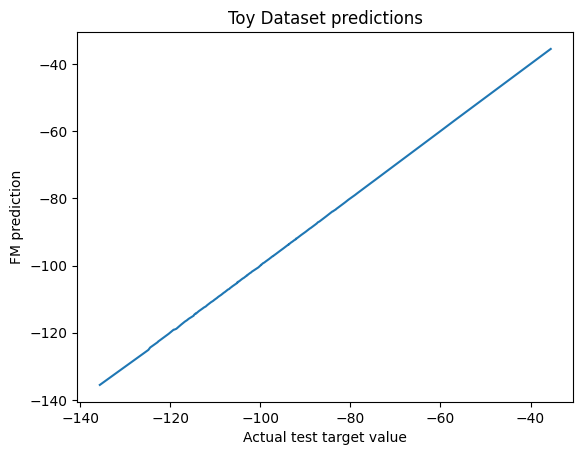

In [ ]:
y_pred = fm_searcher.predict(X_test)

sns.lineplot(x=y_test, y=y_pred)
plt.title("Toy Dataset predictions")
plt.xlabel("Actual test target value")
plt.ylabel("FM prediction")
